# 3 · Testing Linear Classification Models

**Testing a classifier:**
1. **Baseline.** A `DummyClassifier` that always predicts the majority class.
2. **Label metrics.** The confusion matrix → accuracy, precision, recall, F1, balanced accuracy.
3. **Probability metrics.** ROC AUC, PR AUC, log loss, Brier score. These judge the scores themselves, not one threshold.
4. **Calibration.** When the model says 70%, does it happen 70% of the time?
5. **Threshold tuning.** Choose the cutoff that fits the cost of each kind of error.
6. **Cross-validated comparison and learning curve.**
7. **Statistical tests** (statsmodels `Logit`). Coefficient significance and odds ratios.

Dataset: **Titanic** (Kaggle *Titanic*). Predict `survived`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

plt.style.use("seaborn-v0_8-whitegrid")
plt.rc("figure", autolayout=True, figsize=(10, 4))

In [2]:
titanic = fetch_openml("titanic", version=1, as_frame=True).frame
X = titanic[["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]]
y = titanic["survived"].astype(int)
print(y.value_counts(normalize=True).round(3))

survived
0    0.618
1    0.382
Name: proportion, dtype: float64


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

preprocess = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), ["age", "sibsp", "parch", "fare"]),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")),
     ["pclass", "sex", "embarked"]),
])
logreg = make_pipeline(preprocess, LogisticRegression(max_iter=1000))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
logreg.fit(X_train, y_train)

y_pred = logreg.predict(X_test)                 # hard labels (threshold 0.5)
y_prob = logreg.predict_proba(X_test)[:, 1]     # P(survived): most metrics below need this

## 1. Baseline

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Baseline accuracy: {accuracy_score(y_test, dummy.predict(X_test)):.3f}")
print(f"Logistic accuracy: {accuracy_score(y_test, y_pred):.3f}")

Baseline accuracy: 0.619
Logistic accuracy: 0.817


## 2. Label metrics: start from the confusion matrix

|  | predicted 0 | predicted 1 |
|---|---|---|
| **actual 0** | TN | FP |
| **actual 1** | FN | TP |

| Metric | Formula | Answers |
|---|---|---|
| Accuracy | (TP+TN)/all | How often is it right? (misleading when classes are imbalanced) |
| Precision | TP/(TP+FP) | When it says 1, how often is it right? |
| Recall (sensitivity) | TP/(TP+FN) | What share of the real 1s does it find? |
| Specificity | TN/(TN+FP) | What share of the real 0s does it find? |
| F1 | harmonic mean of precision and recall | One number when both matter |
| Balanced accuracy | mean of recall and specificity | Accuracy that holds up under imbalance |

              precision    recall  f1-score   support

        died       0.83      0.89      0.86       203
    survived       0.80      0.70      0.74       125

    accuracy                           0.82       328
   macro avg       0.81      0.79      0.80       328
weighted avg       0.82      0.82      0.81       328

Balanced accuracy: 0.794


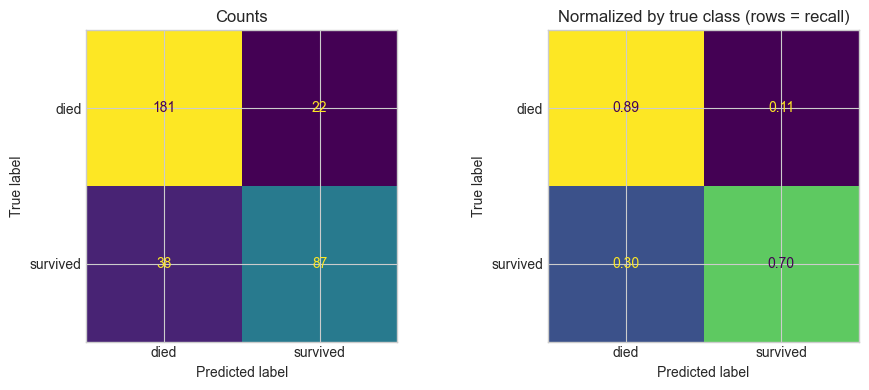

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, balanced_accuracy_score

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["died", "survived"], ax=ax1, colorbar=False)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["died", "survived"], normalize="true",
                                        ax=ax2, colorbar=False, values_format=".2f")
ax1.set_title("Counts"); ax2.set_title("Normalized by true class (rows = recall)")

print(classification_report(y_test, y_pred, target_names=["died", "survived"]))
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.3f}")

## 3. Probability metrics: judge the scores, not one cutoff

| Metric | Measures | Good |
|---|---|---|
| **ROC AUC** | ranking: P(random positive scores above random negative) | 1.0 (0.5 = random) |
| **PR AUC / average precision** | precision–recall trade-off; more informative when positives are rare | 1.0 (baseline = positive rate) |
| **Log loss** | penalizes confident wrong probabilities | lower is better |
| **Brier score** | mean squared error of the probabilities | lower is better |

ROC AUC:           0.855
Average precision: 0.840   (baseline 0.381)
Log loss:          0.437   (baseline 0.665)
Brier score:       0.137


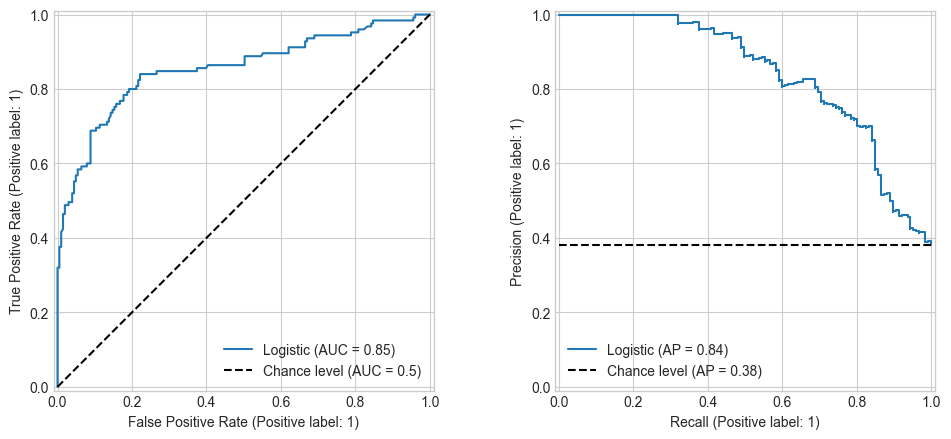

In [6]:
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, brier_score_loss,
                             RocCurveDisplay, PrecisionRecallDisplay)

print(f"ROC AUC:           {roc_auc_score(y_test, y_prob):.3f}")
print(f"Average precision: {average_precision_score(y_test, y_prob):.3f}   (baseline {y_test.mean():.3f})")
print(f"Log loss:          {log_loss(y_test, y_prob):.3f}   (baseline {log_loss(y_test, np.full(len(y_test), y_train.mean())):.3f})")
print(f"Brier score:       {brier_score_loss(y_test, y_prob):.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
RocCurveDisplay.from_predictions(y_test, y_prob, ax=ax1, name="Logistic", plot_chance_level=True)
PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=ax2, name="Logistic", plot_chance_level=True);

## 4. Calibration
Points on the diagonal mean the predicted probabilities can be trusted as probabilities. Logistic regression is usually well calibrated, while trees and SVMs often aren't.

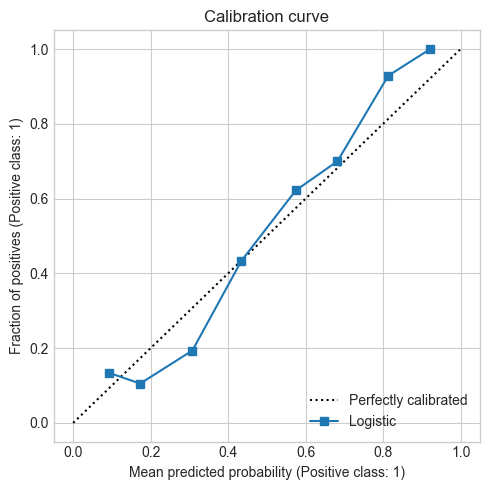

In [7]:
from sklearn.calibration import CalibrationDisplay

fig, ax = plt.subplots(figsize=(5, 5))
CalibrationDisplay.from_predictions(y_test, y_prob, n_bins=8, ax=ax, name="Logistic")
ax.set_title("Calibration curve");

## 5. Choosing the threshold
`predict` uses 0.5. If missing a positive costs more than a false alarm, lower the threshold; in the opposite case, raise it.
Plot the trade-off, then let `TunedThresholdClassifierCV` choose the threshold with CV on the **training** data.

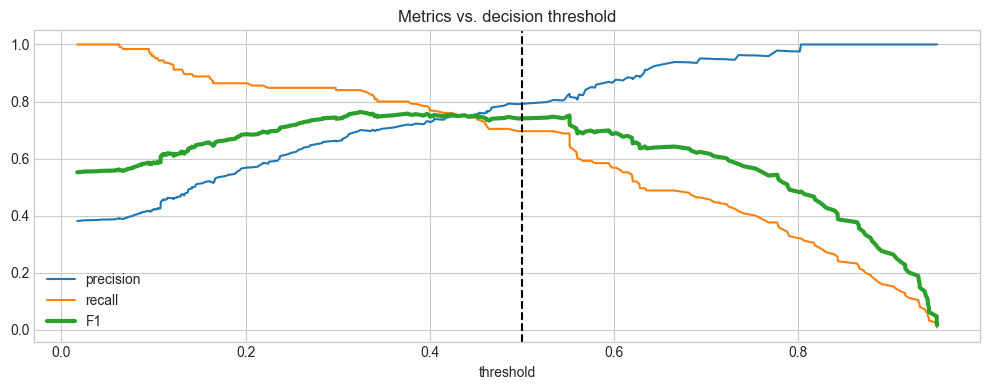

In [8]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(y_test, y_prob)
f1 = 2 * precision * recall / (precision + recall)

fig, ax = plt.subplots()
ax.plot(thresholds, precision[:-1], label="precision")
ax.plot(thresholds, recall[:-1], label="recall")
ax.plot(thresholds, f1[:-1], label="F1", lw=3)
ax.axvline(0.5, ls="--", color="k")
ax.set(xlabel="threshold", title="Metrics vs. decision threshold")
ax.legend();

In [9]:
from sklearn.model_selection import TunedThresholdClassifierCV

tuned = TunedThresholdClassifierCV(logreg, scoring="f1", cv=5).fit(X_train, y_train)
print(f"best threshold (by CV F1): {tuned.best_threshold_:.2f}")

from sklearn.metrics import f1_score
print(f"test F1 @0.50: {f1_score(y_test, y_pred):.3f}   @{tuned.best_threshold_:.2f}: {f1_score(y_test, tuned.predict(X_test)):.3f}")

best threshold (by CV F1): 0.35
test F1 @0.50: 0.744   @0.35: 0.752


## 6. Cross-validated comparison
Use stratified folds and several metrics at once, with the same folds for every model. Here we compare regularization settings.

In [10]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
scoring = ["accuracy", "balanced_accuracy", "f1", "roc_auc", "neg_log_loss"]

candidates = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "L2, C=1": make_pipeline(preprocess, LogisticRegression(C=1, max_iter=1000)),
    "L2, C=0.01": make_pipeline(preprocess, LogisticRegression(C=0.01, max_iter=1000)),
    "L1, C=0.1": make_pipeline(preprocess, LogisticRegression(C=0.1, penalty="l1", solver="liblinear")),
    "L2 + balanced": make_pipeline(preprocess, LogisticRegression(class_weight="balanced", max_iter=1000)),
}
pd.DataFrame({
    name: {s: cross_validate(m, X_train, y_train, cv=cv, scoring=s)["test_score"].mean() for s in scoring}
    for name, m in candidates.items()
}).T.rename(columns={"neg_log_loss": "-log_loss"}).round(3)

,accuracy,balanced_accuracy,f1,roc_auc,-log_loss
Dummy,0.618,0.500,0.000,0.500,-13.778
"L2, C=1",0.774,0.755,0.695,0.831,-0.478
"L2, C=0.01",0.777,0.727,0.639,0.826,-0.535
"L1, C=0.1",0.776,0.757,0.697,0.834,-0.485
L2 + balanced,0.755,0.752,0.698,0.832,-0.497


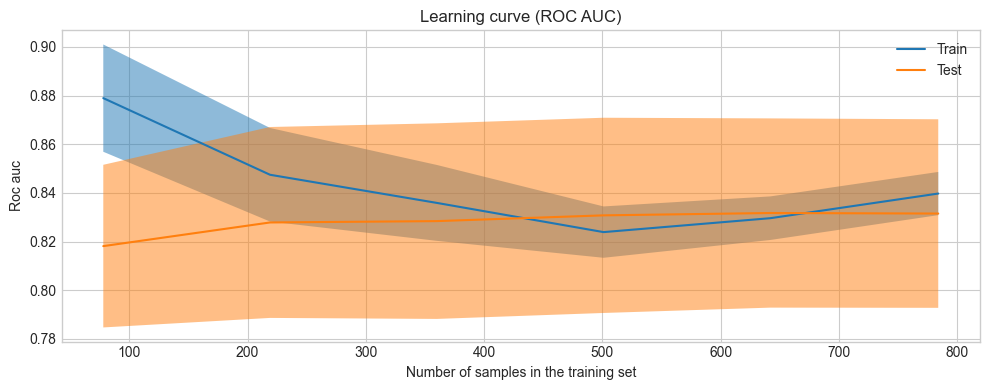

In [11]:
from sklearn.model_selection import LearningCurveDisplay

LearningCurveDisplay.from_estimator(logreg, X_train, y_train, cv=cv, scoring="roc_auc",
                                    train_sizes=np.linspace(0.1, 1.0, 6))
plt.title("Learning curve (ROC AUC)");

## 7. Statistical tests on a logistic model (statsmodels)
The formula API handles the categorical dummies. `C(pclass)` treats class as a category.

In [12]:
import statsmodels.formula.api as smf

df = titanic[["survived", "pclass", "sex", "age", "sibsp", "parch", "fare"]].dropna().astype({"survived": int})
logit = smf.logit("survived ~ C(pclass) + sex + age + sibsp + parch + fare", data=df).fit(disp=False)
logit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:               survived   No. Observations:                 1045
Model:                          Logit   Df Residuals:                     1037
Method:                           MLE   Df Model:                            7
Date:                Thu, 19 Nov 2026   Pseudo R-squ.:                  0.3140
Time:                        22:40:31   Log-Likelihood:                -484.83
converged:                       True   LL-Null:                       -706.79
Covariance Type:            nonrobust   LLR p-value:                 8.972e-92
==================================================================================
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          3.8000      0.397      9.563      0.000       3.021       4.579
C(pclass)[T.2]    -1.2887      0.260     -4.947      0.000      -1.799      -0.778
C(pclass)[T.3]    -2.2575      0.272     -8.302      0.000      -2.791      -1.725
sex[T.male]       -2.5516      0.174    -14.703      0.000      -2.892      -2.211
age               -0.0392      0.007     -5.902      0.000      -0.052      -0.026
sibsp             -0.3589      0.106     -3.388      0.001      -0.566      -0.151
parch              0.0586      0.103      0.569      0.569      -0.143       0.260
fare               0.0012      0.002      0.625      0.532      -0.003       0.005
==================================================================================
"""

**Reading the summary:**
- `coef` is the change in **log-odds** per unit. `z` and `P>|z|` are the Wald test of coef = 0.
- `LLR p-value` is the likelihood-ratio test that the model beats an intercept-only model.
- `Pseudo R-squared` (McFadden) is not the same scale as OLS R². Values of 0.2–0.4 already indicate a good fit.

**Odds ratios** are easier to read: `exp(coef)` is the multiplicative change in the odds of survival.

In [13]:
odds = pd.DataFrame({
    "odds ratio": np.exp(logit.params),
    "2.5%": np.exp(logit.conf_int()[0]),
    "97.5%": np.exp(logit.conf_int()[1]),
    "p-value": logit.pvalues,
}).round(3)
odds

,odds ratio,2.5%,97.5%,p-value
Intercept,44.702,20.516,97.403,0.000
C(pclass)[T.2],0.276,0.165,0.459,0.000
C(pclass)[T.3],0.105,0.061,0.178,0.000
sex[T.male],0.078,0.055,0.110,0.000
age,0.962,0.949,0.974,0.000
sibsp,0.698,0.568,0.860,0.001
parch,1.060,0.867,1.297,0.569
fare,1.001,0.997,1.005,0.532


In [14]:
# Likelihood-ratio test for nested models: does adding 'fare' and 'parch' help?
from scipy import stats

small = smf.logit("survived ~ C(pclass) + sex + age + sibsp", data=df).fit(disp=False)
lr_stat = 2 * (logit.llf - small.llf)
p = stats.chi2.sf(lr_stat, df=logit.df_model - small.df_model)
print(f"LR statistic {lr_stat:.2f}, p = {p:.3f}  → small p means the extra features help")

LR statistic 0.95, p = 0.621  → small p means the extra features help


**Takeaways**
- Compare against a `DummyClassifier`. On imbalanced data, accuracy alone hides a useless model.
- Choose the metric that matches the cost: recall when misses are expensive, precision when false alarms are, ROC AUC or PR AUC for ranking, log loss when the probabilities themselves matter.
- The threshold is a separate decision from the model. Tune it on training CV, not on the test set.
- Use statsmodels `Logit` for significance tests, odds ratios with confidence intervals, and likelihood-ratio tests between nested models.